# Titanic Survival Prediction Using Logistic Regression

## 1. Problem Statement

The Titanic sank in 1912. Some passengers survived and many did not. In this project we look at the passenger data and try to build a model that predicts whether a passenger survived or not.

## 2. Motivation

We want to see how a machine learning model can find patterns in old data and use them to make predictions. Here we look at things like age, gender, passenger class and fare, and check how they are related to survival.

## 3. Dataset Description

We use the Titanic passenger dataset. Each row is one passenger. The target column is `Survived`: **0** means the passenger did not survive and **1** means the passenger survived.



## 4. Import Libraries

In [3]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

print("All libraries imported successfully!")

All libraries imported successfully!


## 5. Load the Dataset



In [4]:
df = pd.read_csv("Titanic-Dataset.csv")
print("Dataset loaded successfully!")

Dataset loaded successfully!


## 6. Initial Dataset Exploration

First we take a quick look at the data: a few rows, how many rows and columns there are, the data type of each column, and how many values are missing.

In [5]:
# First five records
display(df.head())

# Dataset dimensions (rows, columns)
print("Dataset shape:", df.shape)

# Column names, non-null counts and data types
print("\nDataset information:")
df.info()

# Missing values in each column
print("\nMissing values:")
display(df.isnull().sum().to_frame(name="Missing Values"))

,PassengerId,Survived,Pclass,Name,Sex,Age,SibSp,Parch,Ticket,Fare,Cabin,Embarked
0,1,0,3,"Braund, Mr. Owen Harris",male,22.0,1,0,A/5 21171,7.2500,NaN,S
1,2,1,1,"Cumings, Mrs. John Bradley (Florence Briggs Th...",female,38.0,1,0,PC 17599,71.2833,C85,C
2,3,1,3,"Heikkinen, Miss. Laina",female,26.0,0,0,STON/O2. 3101282,7.9250,NaN,S
3,4,1,1,"Futrelle, Mrs. Jacques Heath (Lily May Peel)",female,35.0,1,0,113803,53.1000,C123,S
4,5,0,3,"Allen, Mr. William Henry",male,35.0,0,0,373450,8.0500,NaN,S


Dataset shape: (891, 12)

Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 891 entries, 0 to 890
Data columns (total 12 columns):
 #   Column       Non-Null Count  Dtype  
---  ------       --------------  -----  
 0   PassengerId  891 non-null    int64  
 1   Survived     891 non-null    int64  
 2   Pclass       891 non-null    int64  
 3   Name         891 non-null    object 
 4   Sex          891 non-null    object 
 5   Age          714 non-null    float64
 6   SibSp        891 non-null    int64  
 7   Parch        891 non-null    int64  
 8   Ticket       891 non-null    object 
 9   Fare         891 non-null    float64
 10  Cabin        204 non-null    object 
 11  Embarked     889 non-null    object 
dtypes: float64(2), int64(5), object(5)
memory usage: 83.7+ KB

Missing values:


,Missing Values
PassengerId,0
Survived,0
Pclass,0
Name,0
Sex,0
Age,177
SibSp,0
Parch,0
Ticket,0
Fare,0


## 7. Exploratory Data Analysis (EDA)

In EDA we use tables and simple charts to understand the data. We check how many passengers survived and how survival changes with gender, class and age. These charts only show patterns. They do not prove that one thing caused another.

### 7.1 Overall Survival Distribution

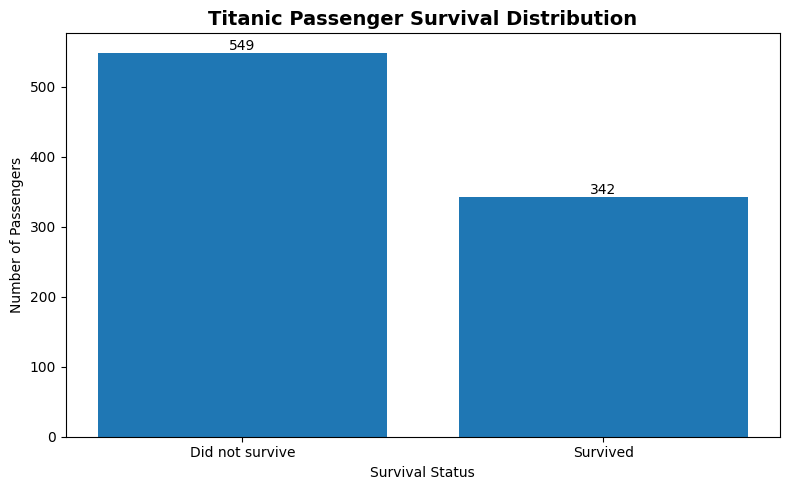

Survival counts:
Survived
0    549
1    342
Name: count, dtype: int64

Survival percentages:
Survived
0    61.6
1    38.4
Name: proportion, dtype: float64


In [6]:
counts = df["Survived"].value_counts().reindex([0, 1])
plt.figure(figsize=(8, 5))
bars = plt.bar(["Did not survive", "Survived"], counts.values)
plt.title("Titanic Passenger Survival Distribution", fontsize=14, fontweight="bold")
plt.xlabel("Survival Status")
plt.ylabel("Number of Passengers")
plt.bar_label(bars)
plt.tight_layout()
plt.show()

print("Survival counts:")
print(counts)
print("\nSurvival percentages:")
print((df["Survived"].value_counts(normalize=True).reindex([0, 1]) * 100).round(1))

**Interpretation:** 549 passengers did not survive and 342 survived. So more people died than survived, and the two classes are not equal in size.

### 7.2 Survival Rate by Gender

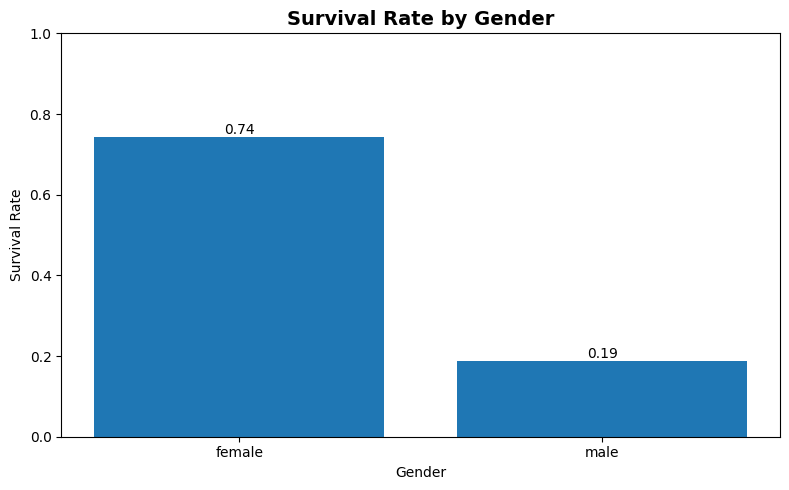

Sex
female    74.2%
male      18.9%
Name: Survived, dtype: object


In [7]:
gender_rates = df.groupby("Sex")["Survived"].mean().reindex(["female", "male"])
plt.figure(figsize=(8, 5))
bars = plt.bar(gender_rates.index, gender_rates.values)
plt.title("Survival Rate by Gender", fontsize=14, fontweight="bold")
plt.xlabel("Gender")
plt.ylabel("Survival Rate")
plt.ylim(0, 1)
plt.bar_label(bars, fmt="%.2f")
plt.tight_layout()
plt.show()

print((gender_rates * 100).round(1).astype(str) + "%")

**Interpretation:** About 74% of women survived, but only about 19% of men did. This is a big difference, so gender is strongly related to survival.

### 7.3 Survival Rate by Passenger Class

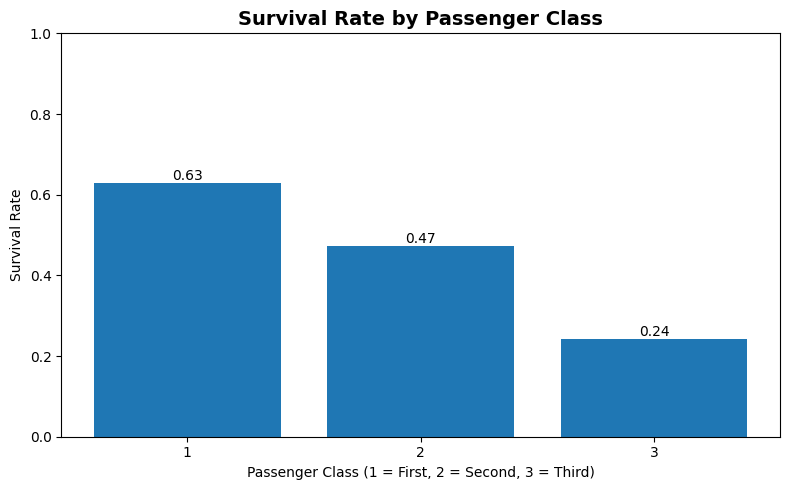

Pclass
1    63.0%
2    47.3%
3    24.2%
Name: Survived, dtype: object


In [8]:
class_rates = df.groupby("Pclass")["Survived"].mean().reindex([1, 2, 3])
plt.figure(figsize=(8, 5))
bars = plt.bar(class_rates.index.astype(str), class_rates.values)
plt.title("Survival Rate by Passenger Class", fontsize=14, fontweight="bold")
plt.xlabel("Passenger Class (1 = First, 2 = Second, 3 = Third)")
plt.ylabel("Survival Rate")
plt.ylim(0, 1)
plt.bar_label(bars, fmt="%.2f")
plt.tight_layout()
plt.show()

print((class_rates * 100).round(1).astype(str) + "%")

**Interpretation:** First-class passengers survived the most (about 63%), then second class (about 47%), and third class the least (about 24%). So passenger class is related to survival.

## 8. EDA Conclusion

From the EDA we found:

1. More passengers died than survived.
2. Women had a much higher survival rate than men.
3. First-class passengers survived more than second- and third-class passengers.
4. The ages of survivors and non-survivors overlap, so age is not very useful on its own.

EDA helps us understand the data, spot missing values and decide which features may be useful before training the Logistic Regression model. These are patterns in this dataset only. They do not prove that any one feature caused survival.

## 9. Data Preprocessing

A Logistic Regression model cannot use the raw data directly. The data has missing values, some columns are text instead of numbers, and the numbers are on very different scales. In this section we clean the data step by step so it is ready for training.

We work on a copy of the data called `df_clean`, so the original `df` used in the EDA stays unchanged.

### 9.1 Import Libraries for Preprocessing

In [9]:
import seaborn as sns
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from collections import Counter

print("Preprocessing libraries imported successfully!")

Preprocessing libraries imported successfully!


### 9.2 Make a Working Copy of the Data

In [10]:
df_clean = df.copy()
print("Working copy created. Shape:", df_clean.shape)

Working copy created. Shape: (891, 12)


### 9.3 Handle Missing Values

From the initial exploration we know three columns have missing values: `Age` (177), `Cabin` (687) and `Embarked` (2). We handle them like this:

- **Age:** filled with the **median**. The median is not pulled up or down by a few very old or very young passengers.
- **Embarked:** filled with the **mode** (the most common port), because it is a category and not a number.
- **Cabin:** most of its values are missing, so filling it would just be guessing. We drop this column in step 9.6.

In [11]:
cols = ["Age", "Embarked", "Cabin"]

print("Missing values BEFORE:")
display(df_clean[cols].isnull().sum().to_frame(name="Missing Values"))

age_median = df_clean["Age"].median()
embarked_counts=Counter(df_clean["Embarked"].dropna())
embarked_mode = embarked_counts.most_common(1)[0][0]
print("Median age used:", age_median)
print("Most common port used:", embarked_mode)

df_clean["Age"] = df_clean["Age"].fillna(age_median)
df_clean["Embarked"] = df_clean["Embarked"].fillna(embarked_mode)

print("\nMissing values AFTER:")
display(df_clean[cols].isnull().sum().to_frame(name="Missing Values"))

Missing values BEFORE:


,Missing Values
Age,177
Embarked,2
Cabin,687


Median age used: 28.0
Most common port used: S

Missing values AFTER:


,Missing Values
Age,0
Embarked,0
Cabin,687


**Interpretation:** `Age` and `Embarked` now have no missing values. We kept all 891 passengers instead of deleting the rows with missing values, so no data was lost.

### 9.4 Encode Text Columns as Numbers

The model only understands numbers, so text columns must be converted.

- **Sex:** has only two values, so we map `male` to 0 and `female` to 1.
- **Embarked:** has three ports (C, Q, S) with no natural order. We use **one-hot encoding**: a separate 0/1 column for each port. We use `drop_first=True` to remove one column, because it can always be worked out from the other two.

In [12]:
df_clean["Sex"] = df_clean["Sex"].map({"male": 0, "female": 1})
df_clean = pd.get_dummies(df_clean, columns=["Embarked"], drop_first=True, dtype=int)

print("Columns after encoding:", df_clean.columns.tolist())
display(df_clean[["Sex", "Embarked_Q", "Embarked_S"]].head())

Columns after encoding: ['PassengerId', 'Survived', 'Pclass', 'Name', 'Sex', 'Age', 'SibSp', 'Parch', 'Ticket', 'Fare', 'Cabin', 'Embarked_Q', 'Embarked_S']


,Sex,Embarked_Q,Embarked_S
0,0,0,1
1,1,0,0
2,1,0,1
3,1,0,1
4,0,0,1


**Interpretation:** `Sex` is now 0 or 1. `Embarked` became two columns, `Embarked_Q` and `Embarked_S`. A passenger with 0 in both columns boarded at Cherbourg (C).

### 9.5 Correlation Analysis

Correlation is a number from -1 to +1 that shows how strongly two columns move together. We are mainly interested in the `Survived` row, because it shows which columns are related to survival. Text columns (`Name`, `Ticket`, `Cabin`) are left out automatically because they are not numbers.

In [13]:
numeric_df = df_clean.select_dtypes(include="number")
corr = numeric_df.corr()

print("Correlation of each column with Survived:")
display(corr["Survived"].drop("Survived").sort_values().to_frame(name="Correlation"))

Correlation of each column with Survived:


,Correlation
Pclass,-0.338481
Embarked_S,-0.149683
Age,-0.064910
SibSp,-0.035322
PassengerId,-0.005007
Embarked_Q,0.003650
Parch,0.081629
Fare,0.257307
Sex,0.543351


**Interpretation:** `Sex` has the strongest positive correlation with `Survived`, so women were more likely to survive. `Pclass` has a clear negative correlation, which means a higher class number (third class) went with lower survival. `Fare` is positively related, which makes sense because first-class tickets cost more. `PassengerId` is almost zero, so it carries no useful information. Columns like `Age`, `SibSp`, `Parch` and the port columns have weaker correlations. *(Check the exact numbers in the table above.)*

Correlation only measures a straight-line relationship between two columns and does not prove cause.

### 9.6 Feature Selection

We keep the columns that carry useful information and drop the rest.

| Dropped column | Reason |
|---|---|
| `PassengerId` | Just a row number. It has almost no correlation with survival. |
| `Name` | Different for every passenger, so a simple model cannot learn from it. |
| `Ticket` | Mostly unique ticket codes. |
| `Cabin` | Most of its values are missing. |

**Kept features:** `Pclass`, `Sex`, `Age`, `SibSp`, `Parch`, `Fare`, `Embarked_Q`, `Embarked_S`.

In [14]:
df_clean = df_clean.drop(columns=["PassengerId", "Name", "Ticket", "Cabin"])

print("Shape after feature selection:", df_clean.shape)
print("Total missing values left:", df_clean.isnull().sum().sum())
display(df_clean.head())

Shape after feature selection: (891, 9)
Total missing values left: 0


,Survived,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_Q,Embarked_S
0,0,3,0,22.0,1,0,7.2500,0,1
1,1,1,1,38.0,1,0,71.2833,0,0
2,1,3,1,26.0,0,0,7.9250,0,1
3,1,1,1,35.0,1,0,53.1000,0,1
4,0,3,0,35.0,0,0,8.0500,0,1


**Interpretation:** The data now has 9 columns: the target `Survived` and 8 input features. All of them are numbers and none has missing values.

### 9.7 Train-Test Split

First we separate the inputs `X` from the answer `y` (the `Survived` column). Then we split the passengers into two groups:

- **Training set (80%):** the model learns from these passengers.
- **Test set (20%):** kept aside to check how well the model works on passengers it has never seen.

`random_state=42` gives the same split every time, so everyone on the team gets the same results. `stratify=y` keeps the survived/not survived ratio the same in both sets.

In [15]:
X = df_clean.drop(columns="Survived")
y = df_clean["Survived"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42, stratify=y
)

print("Training passengers:", len(X_train))
print("Testing passengers: ", len(X_test))
print("Survival rate in training set:", round(y_train.mean(), 3))
print("Survival rate in test set:    ", round(y_test.mean(), 3))

Training passengers: 712
Testing passengers:  179
Survival rate in training set: 0.383
Survival rate in test set:     0.385


**Interpretation:** About 80% of the passengers are used for training and 20% for testing. The survival rate is almost the same in both sets, so the split is fair.

### 9.8 Normalization (Scaling)

The columns have very different ranges. For example `Fare` goes up to hundreds, while `Sex` is only 0 or 1. `StandardScaler` rescales every column to have a mean of 0 and a standard deviation of 1, so that no column dominates just because its numbers are bigger.

**Important:** the scaler learns (`fit`) from the **training data only**, and is then applied (`transform`) to both the training and the test data. If it learned from the test data too, information from the test set would leak into training.

In [16]:
scaler = StandardScaler()

X_train = pd.DataFrame(scaler.fit_transform(X_train), columns=X.columns, index=X_train.index)
X_test = pd.DataFrame(scaler.transform(X_test), columns=X.columns, index=X_test.index)

print("Mean of each column in the training set (should be about 0):")
print(X_train.mean().round(2))
print("\nStandard deviation of each column (should be about 1):")
print(X_train.std().round(2))

Mean of each column in the training set (should be about 0):
Pclass       -0.0
Sex           0.0
Age           0.0
SibSp        -0.0
Parch        -0.0
Fare         -0.0
Embarked_Q   -0.0
Embarked_S    0.0
dtype: float64

Standard deviation of each column (should be about 1):
Pclass        1.0
Sex           1.0
Age           1.0
SibSp         1.0
Parch         1.0
Fare          1.0
Embarked_Q    1.0
Embarked_S    1.0
dtype: float64


**Interpretation:** After scaling, every training column has a mean close to 0 and a standard deviation close to 1, so all features are on the same scale.

### 9.9 Final Check Before Training

In [17]:
print("X_train:", X_train.shape, "  y_train:", y_train.shape)
print("X_test: ", X_test.shape, "  y_test: ", y_test.shape)
print("Missing values in X_train:", X_train.isnull().sum().sum())
print("Missing values in X_test: ", X_test.isnull().sum().sum())
print("\nFeatures used for training:", X_train.columns.tolist())
display(X_train.head())

X_train: (712, 8)   y_train: (712,)
X_test:  (179, 8)   y_test:  (179,)
Missing values in X_train: 0
Missing values in X_test:  0

Features used for training: ['Pclass', 'Sex', 'Age', 'SibSp', 'Parch', 'Fare', 'Embarked_Q', 'Embarked_S']


,Pclass,Sex,Age,SibSp,Parch,Fare,Embarked_Q,Embarked_S
692,0.829568,-0.742427,-0.112078,-0.465084,-0.466183,0.513812,-0.289333,0.611978
481,-0.370945,-0.742427,-0.112078,-0.465084,-0.466183,-0.662563,-0.289333,0.611978
527,-1.571457,-0.742427,-0.112078,-0.465084,-0.466183,3.955399,-0.289333,0.611978
855,0.829568,1.346933,-0.879807,-0.465084,0.727782,-0.467874,-0.289333,0.611978
801,-0.370945,1.346933,0.118241,0.478335,0.727782,-0.115977,-0.289333,0.611978


## 10. Preprocessing Summary

In preprocessing we:

1. Filled the missing `Age` values with the median and the missing `Embarked` values with the mode.
2. Converted `Sex` to 0/1 and one-hot encoded `Embarked`.
3. Used the correlation heatmap to see which columns are related to survival.
4. Dropped `PassengerId`, `Name`, `Ticket` and `Cabin`, and kept 8 features.
5. Split the data 80/20 into training and test sets.
6. Scaled the features with `StandardScaler`, fitted on the training data only.

**The data is now ready for the model.** The next section uses these variables: `X_train`, `X_test`, `y_train`, `y_test` and `scaler`.

## 11. Model Training (Logistic Regression)

Now that the data is ready, we train a **Logistic Regression** model. It learns a weight (coefficient) for each feature from the training set and uses them to estimate the chance that a passenger survived.

We wrap the training step in a small function that fits the model on `X_train` and `y_train` and returns it. Only the training data is used here. The test set stays untouched until we evaluate the model.

### 11.1 Train the Model

In [18]:
from sklearn.linear_model import LogisticRegression


def train_model(X_train, y_train):
    """Fit a Logistic Regression model on the training data and return it."""
    model = LogisticRegression()
    model.fit(X_train, y_train)
    return model


model = train_model(X_train, y_train)
print("Model trained successfully!")
print("Number of features used:", model.n_features_in_)


Model trained successfully!
Number of features used: 8


### 11.2 Model Coefficients

Each coefficient tells us how a feature changes the prediction:

- A **positive** coefficient pushes the prediction towards **survived**.
- A **negative** coefficient pushes it towards **did not survive**.
- A coefficient with a larger absolute value has a stronger effect.

Because we scaled all features with `StandardScaler` in step 9.8, the coefficients are on the same scale, so they can be compared with each other directly.

In [19]:
coef_table = pd.DataFrame({
    "Feature": X_train.columns,
    "Coefficient": model.coef_[0]
})
print(coef_table)
print("Intercept:", round(model.intercept_[0], 3))



      Feature  Coefficient
0      Pclass    -0.928698
1         Sex     1.269598
2         Age    -0.502878
3       SibSp    -0.262672
4       Parch    -0.067158
5        Fare     0.099599
6  Embarked_Q     0.080683
7  Embarked_S    -0.171784
Intercept: -0.657


# 12.Evaluate

After training the Logistic Regression model, we evaluate its performance using the test dataset. The test data was kept separate during training, allowing us to check how well the model predicts outcomes for unseen passengers.

We use accuracy to measure the overall proportion of correct predictions and a confusion matrix to examine the number of correct and incorrect predictions for each survival class. The confusion matrix helps us understand whether the model correctly identifies passengers who survived and those who did not.

Finally, we visualize the confusion matrix and save the plot in the outputs folder for further analysis and presentation.

Accuracy: 80.44692737430168
Confusion Matrix: [[98 12]
 [23 46]]
Precision: 79.3103448275862
Recall: 66.66666666666666
F1-Score: 72.44094488188976


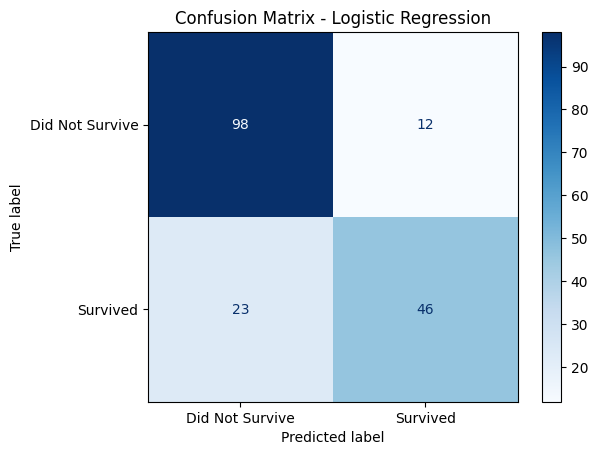

In [22]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    ConfusionMatrixDisplay
)
import matplotlib.pyplot as plt
y_pred = model.predict(X_test)

accuracy = accuracy_score(y_test, y_pred)
print("Accuracy:", accuracy*100)

cm = confusion_matrix(y_test, y_pred)
print("Confusion Matrix:",cm)
precision = precision_score(y_test, y_pred)
recall = recall_score(y_test, y_pred)
f1 = f1_score(y_test, y_pred)
print("Precision:", precision*100)
print("Recall:", recall*100)
print("F1-Score:", f1*100)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Did Not Survive", "Survived"]
)

disp.plot(cmap="Blues")
plt.title("Confusion Matrix - Logistic Regression")
plt.show()

# 13. Prediction Demo

After training and evaluating the Logistic Regression model, we use it to predict whether an individual passenger survived the Titanic disaster. We load the saved model and select one passenger from the test dataset as an example.

The model uses the passenger's features to make a prediction. If the output is 1, the passenger is predicted to have survived. If the output is 0, the passenger is predicted to have not survived.

This demonstrates how the trained model can be used to make predictions on individual passenger data.

In [ ]:
import pandas as pd

sample_passenger = X_test.iloc[[0]]

prediction = model.predict(sample_passenger)

original_passenger = df.loc[sample_passenger.index]

print("Passenger Details:")
print(original_passenger)

if prediction[0] == 1:
    print("Prediction: Survived")
else:
    print("Prediction: Did Not Survive")